In [4]:
import pandas as pd

# Create a sample sales dataset
data = {
    "Order_ID": [101, 102, 103, 104, 105, 105, 106, 107, 108, 109],
    "Customer": ["Arun", "Priya", "Kavi", "Ravi", "Meena",
                 "Meena", "Sanjay", "Divya", "Anu", "Bala"],
    "Product": ["Laptop", " mobile ", "Headphones", "Laptop", "Tablet",
                "Tablet", "MOBILE", "Headphones", "Laptop", "Tablet"],
    "Quantity": [1, 2, None, 1, 3, 3, 2, None, 1, 2],
    "Price": [50000, 15000, 2000, None, 12000, 12000,
              15000, 2000, 50000, 12000],
    "City": ["Chennai", "chennai", "Madurai", "Chennai", None,
             None, "Coimbatore", "MADURAI", "Chennai", "Salem"]
}

df = pd.DataFrame(data)

print("ORIGINAL SALES DATASET")
display(df)

print("\nDataset Shape:", df.shape)

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

ORIGINAL SALES DATASET


,Order_ID,Customer,Product,Quantity,Price,City
0,101,Arun,Laptop,1.0,50000.0,Chennai
1,102,Priya,mobile,2.0,15000.0,chennai
2,103,Kavi,Headphones,NaN,2000.0,Madurai
3,104,Ravi,Laptop,1.0,NaN,Chennai
4,105,Meena,Tablet,3.0,12000.0,None
5,105,Meena,Tablet,3.0,12000.0,None
6,106,Sanjay,MOBILE,2.0,15000.0,Coimbatore
7,107,Divya,Headphones,NaN,2000.0,MADURAI
8,108,Anu,Laptop,1.0,50000.0,Chennai
9,109,Bala,Tablet,2.0,12000.0,Salem



Dataset Shape: (10, 6)

Missing Values in Each Column:
Order_ID    0
Customer    0
Product     0
Quantity    2
Price       1
City        2
dtype: int64

Duplicate Rows: 1


In [5]:
# Step 3: Clean the Sales Dataset

# Keep the original dataset unchanged
clean_df = df.copy()

# 1. Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# 2. Standardize text values
clean_df["Product"] = clean_df["Product"].str.strip().str.title()
clean_df["City"] = clean_df["City"].str.strip().str.title()

# 3. Fill missing values
clean_df["Quantity"] = clean_df["Quantity"].fillna(
    clean_df["Quantity"].median()
)

clean_df["Price"] = clean_df["Price"].fillna(
    clean_df["Price"].median()
)

clean_df["City"] = clean_df["City"].fillna("Unknown")

# 4. Create a Total Sales column
clean_df["Total_Sales"] = clean_df["Quantity"] * clean_df["Price"]

print("CLEANED SALES DATASET")
display(clean_df)

print("\nMissing Values After Cleaning:")
print(clean_df.isnull().sum())

print("\nDuplicate Rows After Cleaning:", clean_df.duplicated().sum())

CLEANED SALES DATASET


,Order_ID,Customer,Product,Quantity,Price,City,Total_Sales
0,101,Arun,Laptop,1.0,50000.0,Chennai,50000.0
1,102,Priya,Mobile,2.0,15000.0,Chennai,30000.0
2,103,Kavi,Headphones,2.0,2000.0,Madurai,4000.0
3,104,Ravi,Laptop,1.0,13500.0,Chennai,13500.0
4,105,Meena,Tablet,3.0,12000.0,Unknown,36000.0
6,106,Sanjay,Mobile,2.0,15000.0,Coimbatore,30000.0
7,107,Divya,Headphones,2.0,2000.0,Madurai,4000.0
8,108,Anu,Laptop,1.0,50000.0,Chennai,50000.0
9,109,Bala,Tablet,2.0,12000.0,Salem,24000.0



Missing Values After Cleaning:
Order_ID       0
Customer       0
Product        0
Quantity       0
Price          0
City           0
Total_Sales    0
dtype: int64

Duplicate Rows After Cleaning: 0


In [6]:
# Step 4: Generate Automated Data Quality Report

report = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Cleaned Rows",
        "Duplicate Rows Removed",
        "Missing Values Before Cleaning",
        "Missing Values After Cleaning",
        "Total Sales Amount"
    ],
    "Value": [
        len(df),
        len(clean_df),
        len(df) - len(clean_df),
        df.isnull().sum().sum(),
        clean_df.isnull().sum().sum(),
        round(clean_df["Total_Sales"].sum(), 2)
    ]
})

print("AUTOMATED DATA QUALITY REPORT")
display(report)

# Save report as CSV
report.to_csv("Data_Quality_Report.csv", index=False)

# Save cleaned dataset as CSV
clean_df.to_csv("Cleaned_Sales_Data.csv", index=False)

print("Report and cleaned dataset saved successfully!")

AUTOMATED DATA QUALITY REPORT


,Metric,Value
0,Original Rows,10.0
1,Cleaned Rows,9.0
2,Duplicate Rows Removed,1.0
3,Missing Values Before Cleaning,5.0
4,Missing Values After Cleaning,0.0
5,Total Sales Amount,241500.0


Report and cleaned dataset saved successfully!


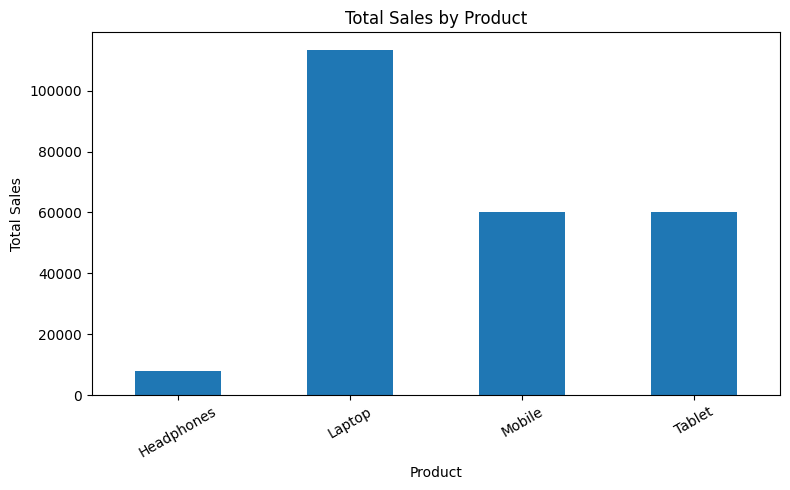

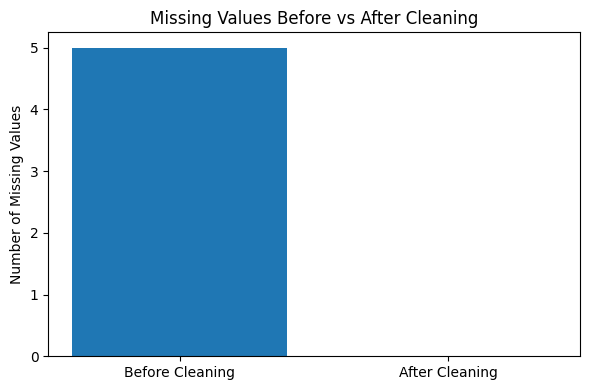

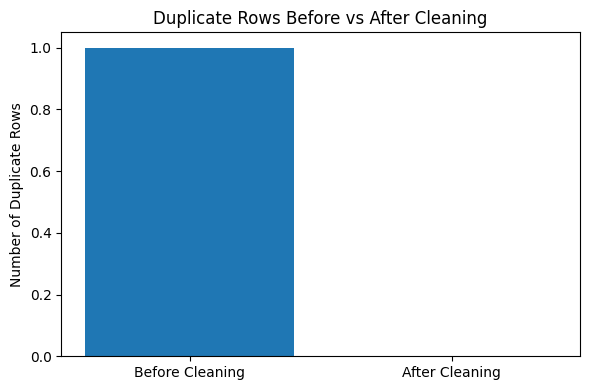

All charts generated successfully!


In [7]:
# Step 5: Create Visual Summaries

import matplotlib.pyplot as plt

# Chart 1: Total Sales by Product
product_sales = clean_df.groupby("Product")["Total_Sales"].sum()

plt.figure(figsize=(8, 5))
product_sales.plot(kind="bar")
plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Chart 2: Missing Values Before and After Cleaning
missing_before = df.isnull().sum().sum()
missing_after = clean_df.isnull().sum().sum()

plt.figure(figsize=(6, 4))
plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [missing_before, missing_after]
)
plt.title("Missing Values Before vs After Cleaning")
plt.ylabel("Number of Missing Values")
plt.tight_layout()
plt.show()

# Chart 3: Duplicate Rows Before and After Cleaning
duplicates_before = df.duplicated().sum()
duplicates_after = clean_df.duplicated().sum()

plt.figure(figsize=(6, 4))
plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [duplicates_before, duplicates_after]
)
plt.title("Duplicate Rows Before vs After Cleaning")
plt.ylabel("Number of Duplicate Rows")
plt.tight_layout()
plt.show()

print("All charts generated successfully!")

In [8]:
# Step 6: Download project output files

from google.colab import files

files.download("Cleaned_Sales_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from google.colab import files

files.download("Data_Quality_Report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import os
print(os.listdir())

['.config', 'Data_Quality_Report.csv', 'Cleaned_Sales_Data.csv', 'sample_data']


In [13]:
import os

print(os.listdir('/content/sample_data'))

['anscombe.json', 'README.md', 'california_housing_test.csv', 'california_housing_train.csv', 'mnist_train_small.csv', 'mnist_test.csv']
